# HSA_Cam_B_009.py
This file uses the LHHW_Model of kinetics to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_005.py is the model. This uses homoscedastic noise and scaled priors.

## First try to actually infer the model

### Plan:
* generate data
* instantiate the model
* infer the model
* check HDIs
* select next experiment at highest HDI

### Results:
* Inference works
* HDIs work
* max HDI strategy does work better now 
* the priors are not updated significantly, which is really bad
* use exponential priors for the kinetic parameters
* next step: implement relative HDI

In [1]:
import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm
import pytensor

import arviz as az
from scipy.optimize import minimize

In [2]:
from HSA_Cam_B_005 import (
    SIDX,
    TRUE_PARAMS,
    _kinetics_model,
    input_p,
    bmodel,
)

# pytensor.config.mode = "JAX"

In [3]:
def post_model_over_T(proposal, idata, key="posterior"):

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        "k0": idata[key]["k0"].values.reshape(1, -1),
        "Ea_k": idata[key]["Ea_k"].values.reshape(1, -1),
        "A_oh": idata[key]["A_oh"].values.reshape(1, -1),
        "dH_oh": idata[key]["dH_oh"].values.reshape(1, -1),
        "A_h2": idata[key]["A_h2"].values.reshape(1, -1),
        "dH_h2": idata[key]["dH_h2"].values.reshape(1, -1),
        "A_mix": idata[key]["A_mix"].values.reshape(1, -1),
        "dH_mix": idata[key]["dH_mix"].values.reshape(1, -1),
    }

    test_res = _kinetics_model(**test_params)
    return test_res


def true_model_over_T(proposal):
    true_res_T = _kinetics_model(
        input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        *TRUE_PARAMS.values(),
    )
    return true_res_T

In [4]:
def post_model_at_proposal(proposal, idata, key="posterior", n_samples=5):

    param_samples = az.extract(idata, group=key, num_samples=n_samples)

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.array(proposal[0]).reshape(1, 1),
        "k0": param_samples["k0"].values.reshape(1, -1),
        "Ea_k": param_samples["Ea_k"].values.reshape(1, -1),
        "A_oh": param_samples["A_oh"].values.reshape(1, -1),
        "dH_oh": param_samples["dH_oh"].values.reshape(1, -1),
        "A_h2": param_samples["A_h2"].values.reshape(1, -1),
        "dH_h2": param_samples["dH_h2"].values.reshape(1, -1),
        "A_mix": param_samples["A_mix"].values.reshape(1, -1),
        "dH_mix": param_samples["dH_mix"].values.reshape(1, -1),
    }

    r = _kinetics_model(**test_params)
    obs_r = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
    return obs_r

In [5]:
def plot_post_model_at_proposal(proposal, test_res, true_res, Ts):
    plt.plot(
        Ts,
        test_res.mean(axis=1),
    )
    plt.plot(
        Ts,
        true_res.squeeze(),
        color="black",
        linestyle="--",
    )
    plt.fill_between(
        x=Ts,
        y1=np.percentile(test_res, 2.5, axis=1),
        y2=np.percentile(test_res, 97.5, axis=1),
        alpha=0.3,
        zorder=0,
    )
    ax = plt.gca()
    ax.text(
        0.05,
        0.95,
        f"pred. @ p={proposal[1]:.2f}, F= {proposal[2]:.2f}, C= {proposal[3]:.2f}, H2= {proposal[4]:.2f}",
        transform=ax.transAxes,
        fontsize=10,
    )
    ax2 = ax.twinx()
    ax2.plot(
        Ts,
        (np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1))
        / np.mean(test_res, axis=1),
        color="orange",
    )

In [6]:
def observe_at_proposal(proposals):
    T = jnp.array([proposals[:, 0]], dtype=jnp.float32).reshape(-1, 1)
    p = jnp.array([proposals[:, 1]], dtype=jnp.float32).reshape(-1, 1)
    c2h = jnp.array([proposals[:, 2]], dtype=jnp.float32).reshape(-1, 1)
    f = jnp.array([proposals[:, 3]], dtype=jnp.float32).reshape(-1, 1)
    c2i = jnp.array([proposals[:, 4]], dtype=jnp.float32).reshape(-1, 1)

    p_i = input_p(p, c2h, f, c2i)

    r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
    r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
    return T, p, c2h, f, c2i, r_obs

In [7]:
T = jnp.array([560, 570, 580], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array([4, 5, 6], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array([1], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array([1000], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array([0.5], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
print(r)
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
print(r_obs)

[[9.99750078e-01 9.99750078e-01 0.00000000e+00 9.99750078e-04
  1.99950016e+00]
 [1.24968760e+00 1.24968760e+00 0.00000000e+00 1.24968760e-03
  2.49937519e+00]
 [1.49962512e+00 1.49962512e+00 0.00000000e+00 1.49962512e-03
  2.99925023e+00]]
[[7.61192633e-05]
 [1.16399861e-04]
 [1.72598760e-04]]
[[8.56923350e-05]
 [1.06700571e-04]
 [1.82669424e-04]]


In [8]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = input_p(p, c2h, f, c2i)
    res = _kinetics_model(
        p_i,
        T,
        idata[key]["k0"].values.reshape(1, -1),
        idata[key]["Ea_k"].values.reshape(1, -1),
        idata[key]["A_oh"].values.reshape(1, -1),
        idata[key]["dH_oh"].values.reshape(1, -1),
        idata[key]["A_h2"].values.reshape(1, -1),
        idata[key]["dH_h2"].values.reshape(1, -1),
        idata[key]["A_mix"].values.reshape(1, -1),
        idata[key]["dH_mix"].values.reshape(1, -1),
    )
    HDI = jnp.percentile(res, 97.5) - jnp.percentile(res, 2.5)
    return -HDI

In [9]:
def detect_transformed_keys(model: pm.Model) -> dict[str, str]:
    """
    Inspect model.initial_point() to find whether a variable uses a transformed name.
    Returns mapping constrained_name -> key_expected_by_compiled_logp.
    Heuristics cover common transforms: log (-> name_log__), logit (-> name_interval__),
    but in general we fall back to the same name if present.
    """
    init = model.initial_point()
    mapping = {}
    for name in model.named_vars:
        constrained = name
        if constrained in init:
            mapping[constrained] = constrained
        elif f"{constrained}_log__" in init:
            mapping[constrained] = f"{constrained}_log__"
        elif f"{constrained}_interval__" in init:
            mapping[constrained] = f"{constrained}_interval__"
        else:
            # fallback: try to find any init key that contains the var name
            found = [k for k in init.keys() if k.startswith(constrained)]
            mapping[constrained] = found[0] if found else constrained
    return mapping


def build_point_for_compiled(mapping: dict[str, str], sample_dict):
    """
    Given a mapping constrained->compiled_key and a sample of constrained vars (sample_dict),
    return a point dict suitable for compiled_logp. For common transforms we apply inverse transform:
      - If compiled_key endswith '_log__' -> pass np.log(value)
      - If compiled_key endswith '_interval__' -> pass logit(value) = log(p/(1-p))
    Otherwise pass the raw constrained value.
    """

    def safe_log(x):
        return np.log(np.maximum(x, 1e-300))

    def safe_logit(x):
        x = np.clip(x, 1e-12, 1 - 1e-12)
        return np.log(x / (1 - x))

    point = {}
    for constrained_name, compiled_key in mapping.items():
        if constrained_name not in sample_dict:
            continue  # maybe a deterministic / not in sample
        val = sample_dict[constrained_name]
        if compiled_key.endswith("_log__"):
            point[compiled_key] = safe_log(val)
        elif compiled_key.endswith("_interval__"):
            point[compiled_key] = safe_logit(val)
        else:
            point[compiled_key] = val
    return point

In [10]:
def KL_divergence(model, x, y, x_new, idata, key="posterior", n_hyp_samples=5):
    base_logp = model.compile_logp()
    base_mapping = detect_transformed_keys(model)

    # draw the hypothetical samples from the posterior
    y_new = post_model_at_proposal(
        x_new,
        idata,
        key=key,
        n_samples=n_hyp_samples,
    )
    klds = jnp.zeros(n_hyp_samples)
    for i in range(n_hyp_samples):
        print(f"Hypothetical sample {i + 1}/{n_hyp_samples}")
        # append the hypothetical observation to the existing data
        # generate the new parameters at which to observe
        x_adj = jnp.vstack([x, x_new])
        # generate the new actual parameters, omit the observed data though
        T_adj, p_adj, c2h_adj, f_adj, c2i_adj, _ = observe_at_proposal(x_adj)
        # append the hypothetical observation to the existing data
        y_adj = jnp.vstack([y, y_new[i].reshape(1, 1)])
        # build the adjusted model
        adj_model = bmodel(
            (
                np.asarray(T_adj),
                np.asarray(p_adj),
                np.asarray(c2h_adj),
                np.asarray(f_adj),
                np.asarray(c2i_adj),
            ),
            np.asarray(y_adj),
        )
        # very quickly and imprecisely sample from the adjusted model
        with adj_model:
            approx = pm.fit(n=10000, method="advi")
            adj_trace = approx.sample(1000)
        # build the adjusted logp function
        adj_logp = adj_model.compile_logp()
        adj_mapping = detect_transformed_keys(adj_model)
        # extract the posterior samples from the adjusted model
        posterior_theta_samples = az.extract(
            adj_trace,
            group="posterior",
            var_names=[
                "~y_hat",
                "~k0",
                "~Ea_k",
                "~A_oh",
                "~dH_oh",
                "~A_h2",
                "~dH_h2",
                "~A_mix",
                "~dH_mix",
            ],  # exclude predictive and deterministic variables
        )
        post_dict = {}
        for var in posterior_theta_samples.data_vars:
            post_dict[var] = posterior_theta_samples[var].values
        # compute the KL divergence component for this hypothetical sample
        logp_old = np.empty(500)
        logp_new = np.empty(500)
        for j in range(500):
            sample_dict = {k: v[j] for k, v in post_dict.items()}
            point_new = build_point_for_compiled(adj_mapping, sample_dict)
            point_old = build_point_for_compiled(base_mapping, sample_dict)
            logp_new[j] = adj_logp(point_new)
            logp_old[j] = base_logp(point_old)
        kl_div_i = jnp.mean(logp_new - logp_old)
        klds[i] = kl_div_i

    return np.mean(klds)

In [11]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [12]:
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000)

Sampling: [A_h2_s, A_mix_s, A_oh_s, Ea_k_s, LH2, dH_h2_s, dH_mix_s, dH_oh_s, k0_s, sigma_r_s]


In [13]:
# sol = minimize(
#     max_func,
#     jnp.array([555.0, 15.0, 0.5, 1000.0, 0.5]),
#     args=(prior_idata, "prior"),
#     bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
#     method="Nelder-Mead",
# )
# proposals = np.atleast_2d(sol.x)
# print(proposals)

generate the first 4 points on purpose

In [14]:
proposals = np.array(
    [
        [500.0, 4.0, 0.5, 1000.0, 0.5],
        [600.0, 4.0, 0.5, 1000.0, 0.5],
        [500.0, 20.0, 0.5, 1000.0, 0.5],
        [600.0, 20.0, 0.5, 1000.0, 0.5],
    ]
)

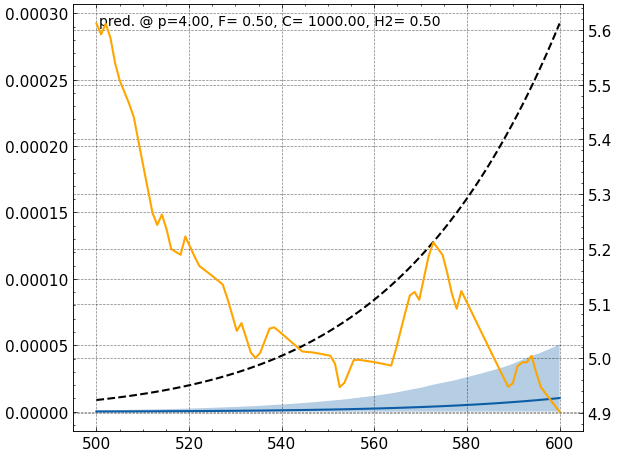

In [15]:
Ts = jnp.linspace(500, 600, 100)
r = post_model_over_T(proposals[0], prior_idata, key="prior")
true_res = true_model_over_T(proposals[0])
plot_post_model_at_proposal(proposals[0], r, true_res, Ts)

## Automatic Iteration

In [16]:
n_iterations = 8
i_datas = []
max_HDIs = []

In [ ]:
for i in range(n_iterations):
    print(f"Iteration {i+1}/{n_iterations}")
    T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)
    model = bmodel(
        (
            np.asarray(T),
            np.asarray(p),
            np.asarray(c2h),
            np.asarray(f),
            np.asarray(c2i),
        ),
        np.asarray(r_obs),
    )
    with model:
        idata = pm.sample(
            tune=1000,
            draws=4000,
            chains=4,
            target_accept=0.9,
            return_inferencedata=True,
        )
        i_datas.append(idata)
    sol = minimize(
        max_func,
        jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
        args=(idata, "posterior"),
        bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
        method="Nelder-Mead",
    )
    max_HDIs.append(-sol.fun)
    proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
    print("Next Proposal:\n", sol.x)

Iteration 1/8


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0_s, Ea_k_s, A_oh_s, dH_oh_s, A_h2_s, dH_h2_s, A_mix_s, dH_mix_s, sigma_r_s]


Output()

Sampling 3 chains for 1_000 tune and 181 draw iterations (3_000 + 543 draws total) took 151 seconds.
There were 23 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Next Proposal:
 [ 600.   20.    2. 1000.    1.]
Iteration 2/8


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0_s, Ea_k_s, A_oh_s, dH_oh_s, A_h2_s, dH_h2_s, A_mix_s, dH_mix_s, sigma_r_s]


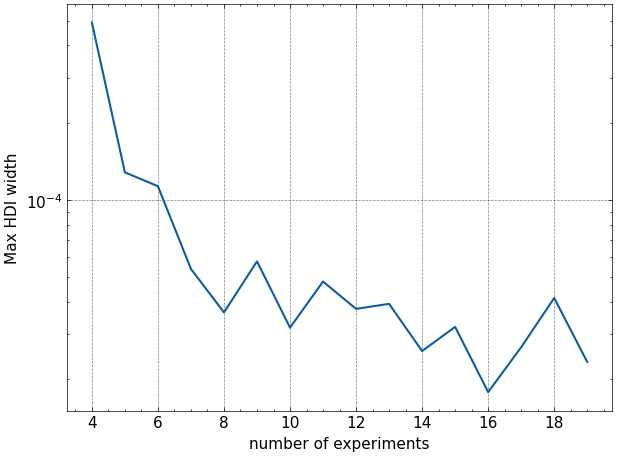

In [ ]:
plt.plot(np.arange(len(max_HDIs)) + 4, max_HDIs)
plt.xlabel("number of experiments")
plt.ylabel("Max HDI width")
plt.yscale("log")
plt.show()

In [ ]:
for i, idata in enumerate(i_datas):
    if i == 0:
        idata.prior = prior_idata.prior
    else:
        idata.prior = i_datas[i - 1].posterior

array([[<Axes: >, <Axes: >, <Axes: xlabel='Ea_k'>]], dtype=object)

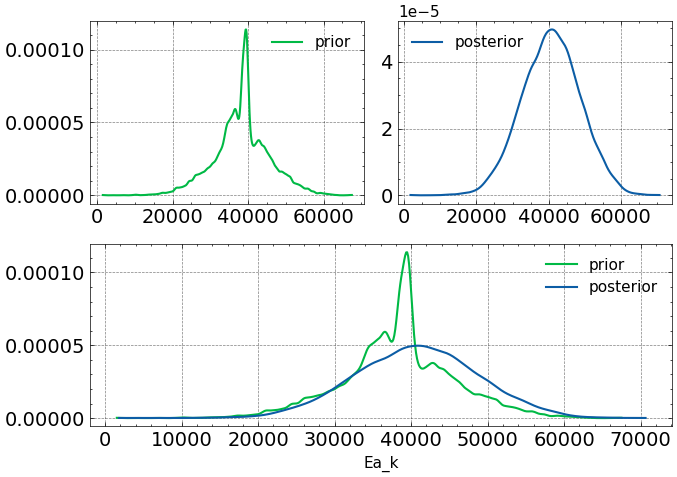

In [ ]:
import ICIW_Plots

plt.style.use("ICIWstyle")
az.plot_dist_comparison(i_datas[4], var_names=["Ea_k"], figsize=(7, 5))

array([[<Axes: title={'center': 'k0_s'}>,
        <Axes: title={'center': 'k0_s'}>],
       [<Axes: title={'center': 'Ea_k_s'}>,
        <Axes: title={'center': 'Ea_k_s'}>],
       [<Axes: title={'center': 'A_oh_s'}>,
        <Axes: title={'center': 'A_oh_s'}>],
       [<Axes: title={'center': 'dH_oh_s'}>,
        <Axes: title={'center': 'dH_oh_s'}>],
       [<Axes: title={'center': 'A_h2_s'}>,
        <Axes: title={'center': 'A_h2_s'}>],
       [<Axes: title={'center': 'dH_h2_s'}>,
        <Axes: title={'center': 'dH_h2_s'}>],
       [<Axes: title={'center': 'A_mix_s'}>,
        <Axes: title={'center': 'A_mix_s'}>],
       [<Axes: title={'center': 'dH_mix_s'}>,
        <Axes: title={'center': 'dH_mix_s'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>],
       [<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': '

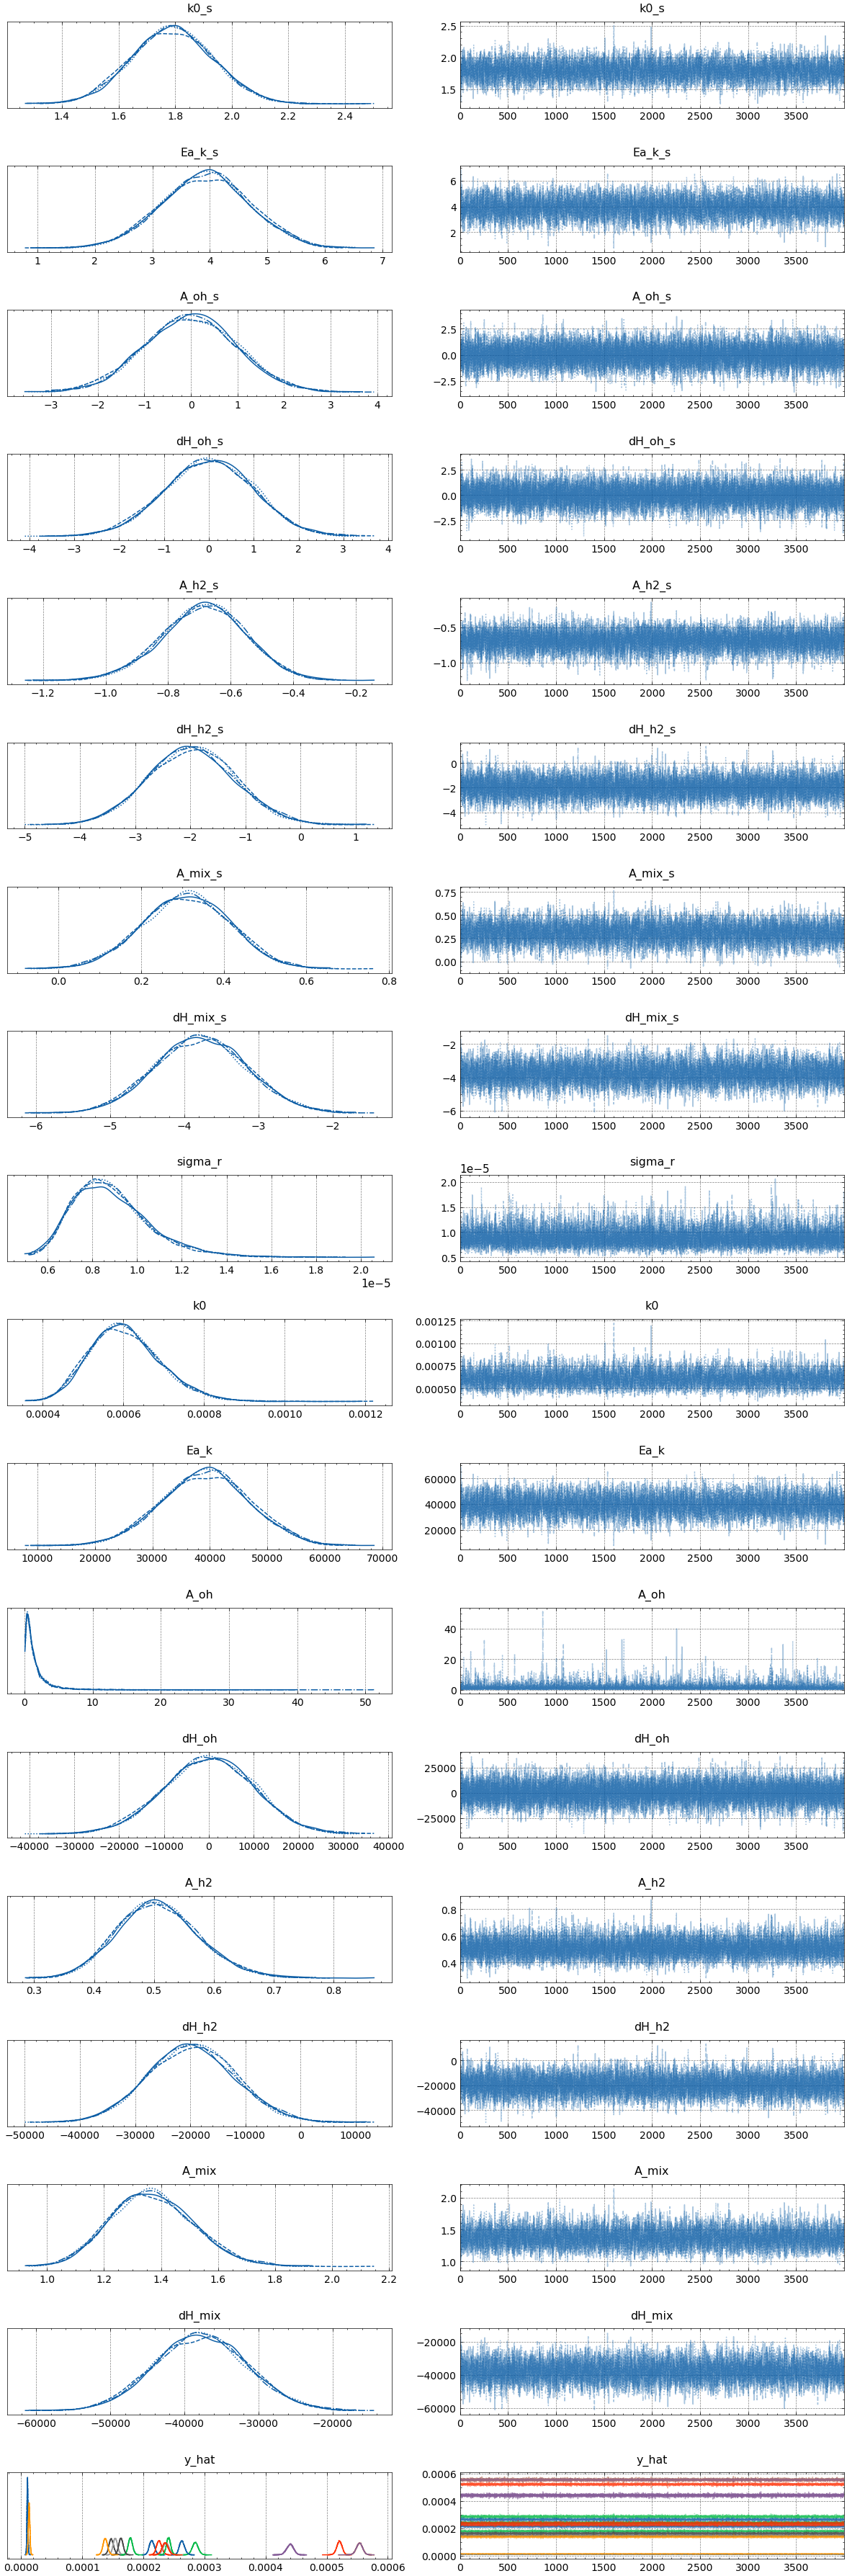

In [ ]:
az.plot_trace(i_datas[-1])

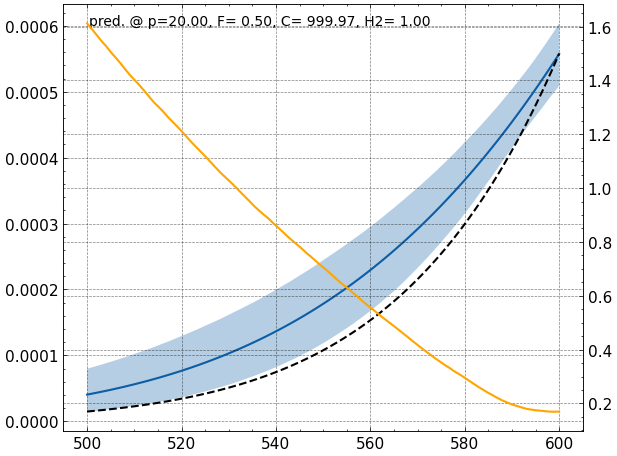

In [ ]:
i = 5
# test_res = post_model_over_T(proposals[i], prior_idata, key="prior")
r = post_model_over_T(proposals[i], i_datas[1], key="posterior")
true_res_T = true_model_over_T(proposals[i])
plot_post_model_at_proposal(proposals[i], r, true_res_T, Ts)

In [ ]:
display(pm.summary(idata, hdi_prob=0.95))

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
k0_s,1.791,0.144,1.509,2.066,0.002,0.001,5067.0,7016.0,1.0
Ea_k_s,3.929,0.762,2.458,5.423,0.011,0.007,4967.0,7552.0,1.0
A_oh_s,-0.009,0.996,-1.942,1.962,0.008,0.009,14545.0,10797.0,1.0
dH_oh_s,-0.000,0.997,-2.039,1.853,0.009,0.008,13518.0,10628.0,1.0
A_h2_s,-0.686,0.135,-0.961,-0.431,0.002,0.001,7161.0,8685.0,1.0
dH_h2_s,-1.972,0.786,-3.498,-0.425,0.009,0.006,7544.0,8981.0,1.0
A_mix_s,0.309,0.107,0.102,0.517,0.001,0.001,5379.0,7504.0,1.0
dH_mix_s,-3.772,0.618,-4.942,-2.516,0.008,0.005,5710.0,7818.0,1.0
sigma_r,0.000,0.000,0.000,0.000,0.000,0.000,9631.0,8375.0,1.0
k0,0.001,0.000,0.000,0.001,0.000,0.000,5067.0,7016.0,1.0


### Generate the exploration pattern

C:\Users\hanne\AppData\Local\Temp\ipykernel_8860\2035428282.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


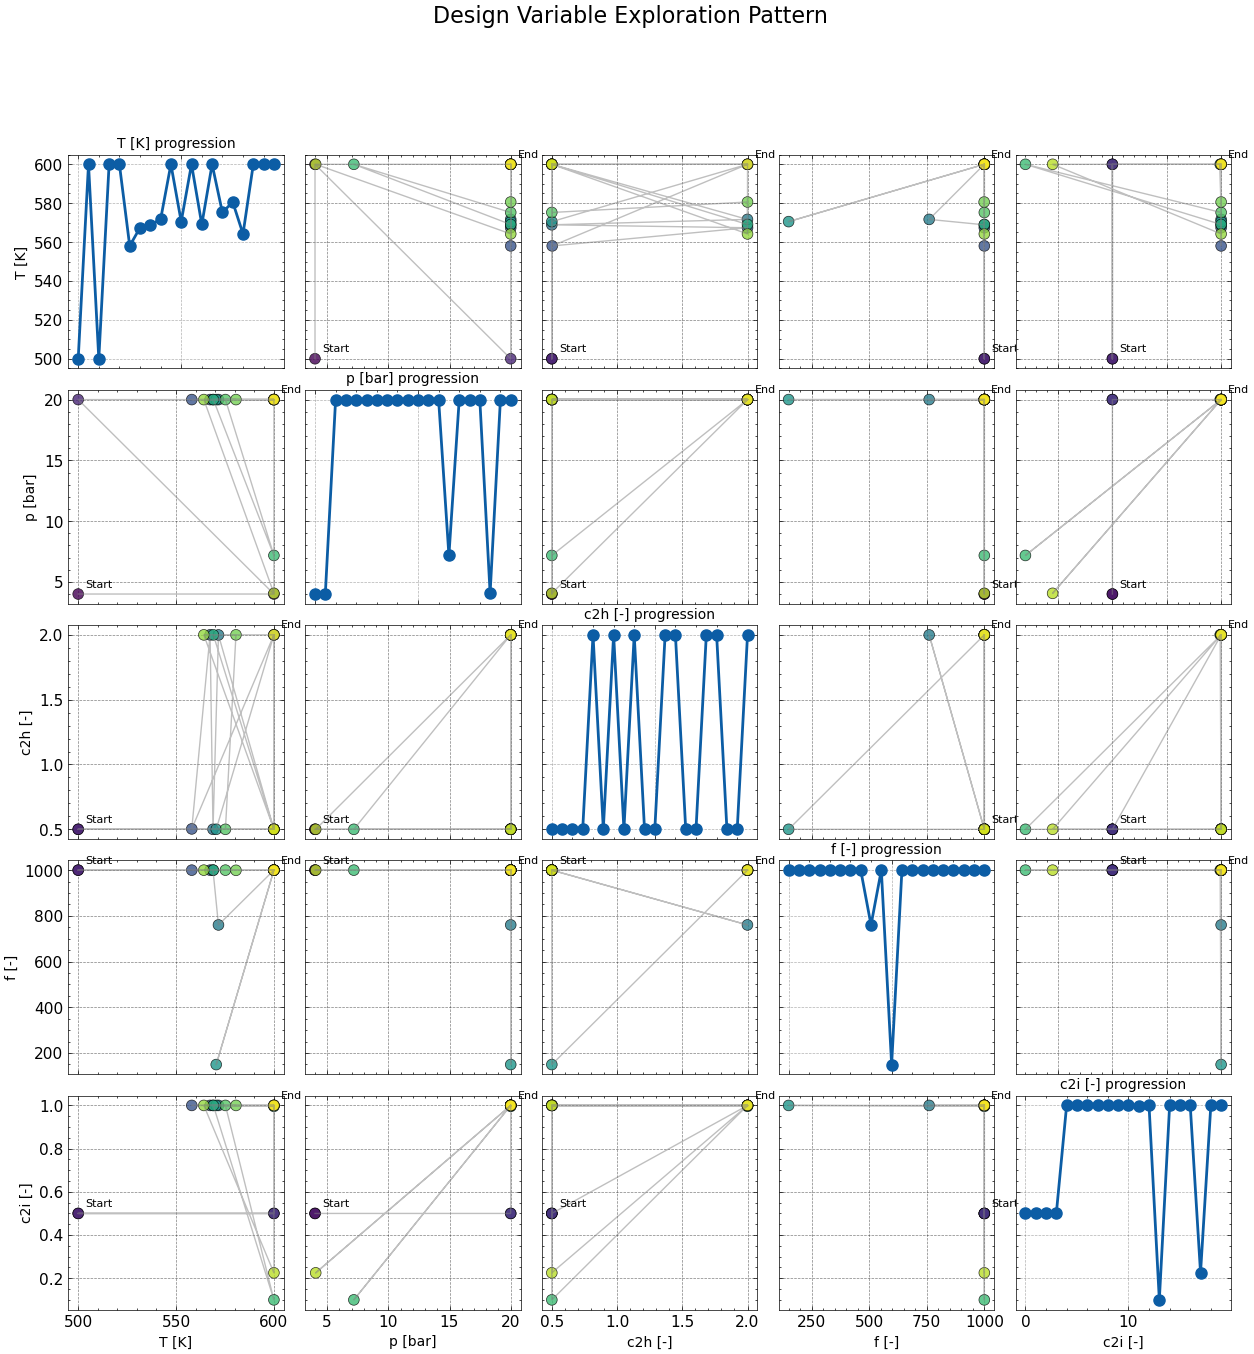

In [ ]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = ["T [K]", "p [bar]", "c2h [-]", "f [-]", "c2i [-]"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

<Axes: xlabel='Ea_k_s', ylabel='k0_s'>

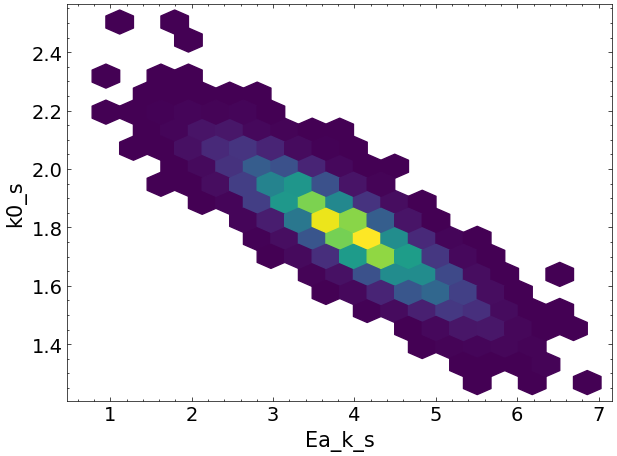

In [ ]:
pm.plot_pair(idata, var_names=["Ea_k_s", "k0_s"], kind="hexbin")

In [ ]:
az.extract(i_datas[-1], group="posterior", num_samples=25)

<xarray.Dataset> Size: 8kB
Dimensions:      (sample: 25, y_hat_dim_0: 19, y_hat_dim_1: 1)
Coordinates:
  * y_hat_dim_0  (y_hat_dim_0) int64 152B 0 1 2 3 4 5 6 ... 12 13 14 15 16 17 18
  * y_hat_dim_1  (y_hat_dim_1) int64 8B 0
  * sample       (sample) object 200B MultiIndex
  * chain        (sample) int64 200B 3 2 1 1 0 2 1 0 3 1 ... 1 3 1 0 1 2 2 0 2 3
  * draw         (sample) int64 200B 1029 3921 934 2082 ... 3820 361 3543 2000
Data variables: (12/18)
    k0_s         (sample) float64 200B 1.664 2.102 1.863 ... 1.869 1.673 1.783
    Ea_k_s       (sample) float64 200B 4.553 2.467 3.878 ... 2.903 4.21 4.325
    A_oh_s       (sample) float64 200B -1.487 1.846 -0.1197 ... 0.1924 0.6047
    dH_oh_s      (sample) float64 200B -0.9923 1.565 -0.005997 ... 1.041 1.322
    A_h2_s       (sample) float64 200B -0.6999 -0.4947 ... -0.8925 -0.7064
    dH_h2_s      (sample) float64 200B -1.934 -2.712 -0.8665 ... -1.378 -2.269
    ...           ...
    dH_oh        (sample) float64 200B -9.923e+03 1.565e+04 ... 1.322e+04
    A_h2         (sample) float64 200B 0.4966 0.6098 0.4642 ... 0.4096 0.4934
    dH_h2        (sample) float64 200B -1.934e+04 -2.712e+04 ... -2.269e+04
    A_mix        (sample) float64 200B 1.208 1.626 1.512 ... 1.397 1.4 1.336
    dH_mix       (sample) float64 200B -3.116e+04 -4.651e+04 ... -3.074e+04
    y_hat        (y_hat_dim_0, y_hat_dim_1, sample) float64 4kB 1.108e-05 ......
Attributes:
    created_at:                 2025-10-17T14:18:17.377018+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.25.1
    sampling_time:              342.2839787006378
    tuning_steps:               1000